In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path
import pandas as pd

In [2]:

metrics = [
        "hidden_dim",
        "dropout_rate",
        "learning_rate",
        "val_loss",
        "ARI",
        "NMI",
        "accuracy",
        "macro_F1",
        "val_pred",
        "val_error"
]

numeric_cols = [
    "dropout_rate",
    "learning_rate",
    "val_loss",
    "ARI",
    "NMI",
    "accuracy",
    "macro_F1",
    "val_error",
]

FileNotFoundError: [Errno 2] No such file or directory: '/home/tobiasocula/Documents/Battery-Analysis-ML-DL/visualize_metrics_df/saves/supervised_DL/label_A.npy'

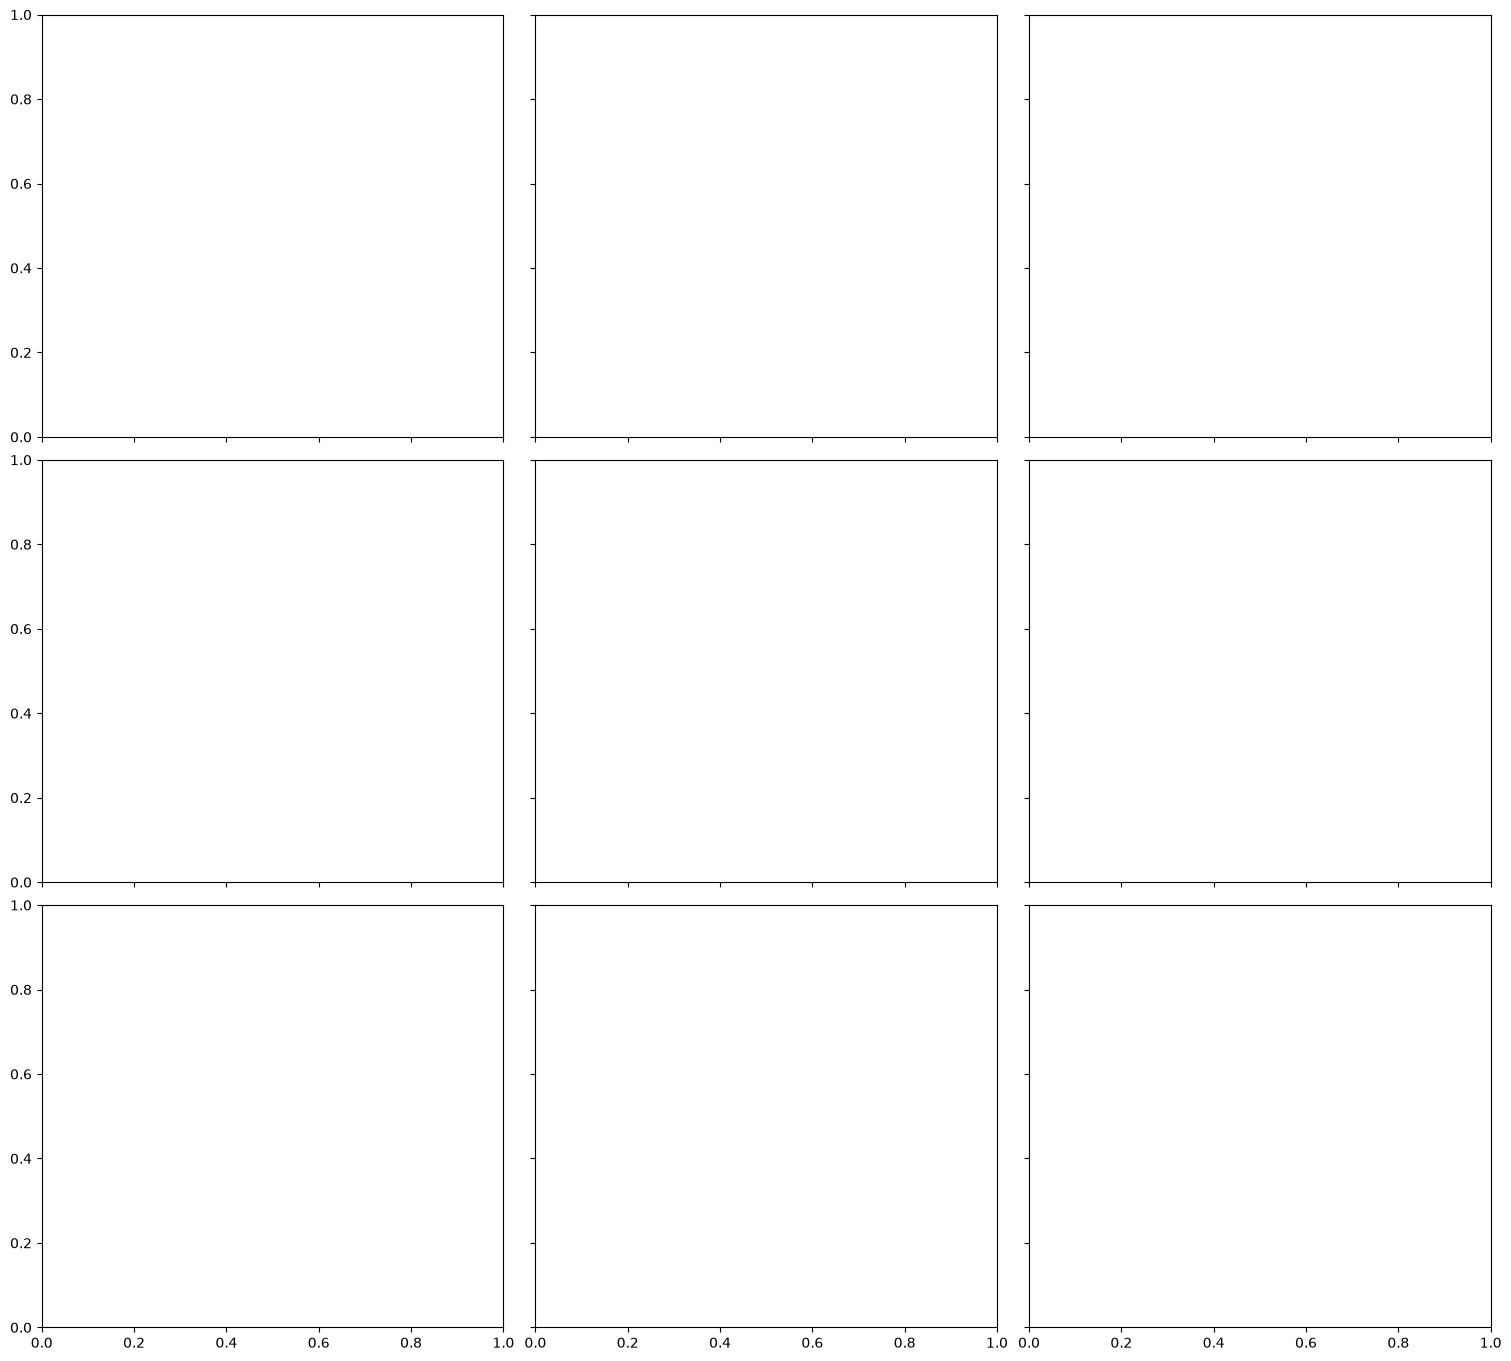

In [3]:
labels = ["A", "B", "C"]

architectures = [
    (128, 64),
    (64, 32, 16),
    (128, 64, 32)
]

fig, axes = plt.subplots(
    len(labels), len(architectures),
    figsize=(5 * len(architectures), 4.5 * len(labels)),
    sharey="row",
    sharex="col",
    layout="constrained"
)

# Optional: use one common colour scale across every label and architecture
all_val_errors = []

for label in labels:
    metrics_df = np.load(
        Path.cwd() / "saves" / "supervised_DL" / f"label_{label}.npy",
        allow_pickle=True
    )
    metrics_df = pd.DataFrame(metrics_df, columns=metrics)

    for col in numeric_cols:
        metrics_df[col] = pd.to_numeric(metrics_df[col], errors="coerce")

    all_val_errors.extend(metrics_df["val_error"].dropna().to_numpy())

vmin = min(all_val_errors)
vmax = max(all_val_errors)

for i, label in enumerate(labels):
    metrics_df = np.load(
        Path.cwd() / "saves" / "supervised_DL" / f"label_{label}.npy",
        allow_pickle=True
    )
    metrics_df = pd.DataFrame(metrics_df, columns=metrics)

    for col in numeric_cols:
        metrics_df[col] = pd.to_numeric(metrics_df[col], errors="coerce")

    for j, arch in enumerate(architectures):
        ax = axes[i, j]

        pivot = (
            metrics_df[metrics_df["hidden_dim"] == arch]
            .pivot(
                index="dropout_rate",
                columns="learning_rate",
                values="val_error"
            )
            .sort_index()
            .sort_index(axis=1)
        )

        sns.heatmap(
            pivot,
            annot=True,
            fmt=".3f",
            cmap="viridis_r",  # lower error = better
            vmin=vmin,
            vmax=vmax,
            cbar=(j == len(architectures) - 1),
            cbar_kws={"label": "Validation error"},
            ax=ax
        )

        ax.set_title(f"Label {label}\nArchitecture: {arch}")
        ax.set_xlabel("Learning rate")
        ax.set_ylabel("Dropout rate")

fig.suptitle("Validation error by hyperparameters", fontsize=16)

plt.savefig(
    Path.cwd() / "images" / "supervised_MLP" / "hyperparameter_grids.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()